In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder

In [2]:
df = pd.read_csv("Housing.csv")
print(df.shape[0], df.shape[1])
df.info()

545 13
<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 69.2 KB


In [3]:
missing = pd.DataFrame({
    "Missing": df.isnull().sum(),
    "Percent": (df.isnull().mean() * 100).round(2)
})
print("Missing values summary:")
print(missing)

Missing values summary:
                  Missing  Percent
price                   0      0.0
area                    0      0.0
bedrooms                0      0.0
bathrooms               0      0.0
stories                 0      0.0
mainroad                0      0.0
guestroom               0      0.0
basement                0      0.0
hotwaterheating         0      0.0
airconditioning         0      0.0
parking                 0      0.0
prefarea                0      0.0
furnishingstatus        0      0.0


In [4]:
df_clean = df.copy()
numeric_cols = df_clean.select_dtypes(include=np.number).columns
categorical_cols = df_clean.select_dtypes(exclude=np.number).columns

for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

for col in categorical_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

print("Total missing values after imputation:", df_clean.isnull().sum().sum())

Total missing values after imputation: 0


In [5]:
for col in categorical_cols:
    print(col, df_clean[col].unique())

df_encoded = pd.get_dummies(df_clean, columns=categorical_cols, drop_first=True)
print("Encoded shape:", df_encoded.shape)
print(df_encoded.head())

demo_col = "furnishingstatus"
codes = LabelEncoder().fit_transform(df_clean[demo_col].astype(str))
print(pd.DataFrame({demo_col: df_clean[demo_col], "Encoded": codes}).head())

mainroad <ArrowStringArray>
['yes', 'no']
Length: 2, dtype: str
guestroom <ArrowStringArray>
['no', 'yes']
Length: 2, dtype: str
basement <ArrowStringArray>
['no', 'yes']
Length: 2, dtype: str
hotwaterheating <ArrowStringArray>
['no', 'yes']
Length: 2, dtype: str
airconditioning <ArrowStringArray>
['yes', 'no']
Length: 2, dtype: str
prefarea <ArrowStringArray>
['yes', 'no']
Length: 2, dtype: str
furnishingstatus <ArrowStringArray>
['furnished', 'semi-furnished', 'unfurnished']
Length: 3, dtype: str
Encoded shape: (545, 14)
      price  area  bedrooms  bathrooms  stories  parking  mainroad_yes  \
0  13300000  7420         4          2        3        2          True   
1  12250000  8960         4          4        4        3          True   
2  12250000  9960         3          2        2        2          True   
3  12215000  7500         4          2        2        3          True   
4  11410000  7420         4          1        2        2          True   

   guestroom_yes  basement

In [6]:
std_df = pd.DataFrame(StandardScaler().fit_transform(df_clean[numeric_cols]), columns=numeric_cols)
mm_df = pd.DataFrame(MinMaxScaler().fit_transform(df_clean[numeric_cols]), columns=numeric_cols)

print("Standard Scaler summary:\n", std_df.agg(["mean", "std"]).round(2))
print("MinMax Scaler summary:\n", mm_df.agg(["min", "max"]).round(2))

Standard Scaler summary:
       price  area  bedrooms  bathrooms  stories  parking
mean    0.0  -0.0      -0.0       -0.0     -0.0      0.0
std     1.0   1.0       1.0        1.0      1.0      1.0
MinMax Scaler summary:
      price  area  bedrooms  bathrooms  stories  parking
min    0.0   0.0       0.0        0.0      0.0      0.0
max    1.0   1.0       1.0        1.0      1.0      1.0


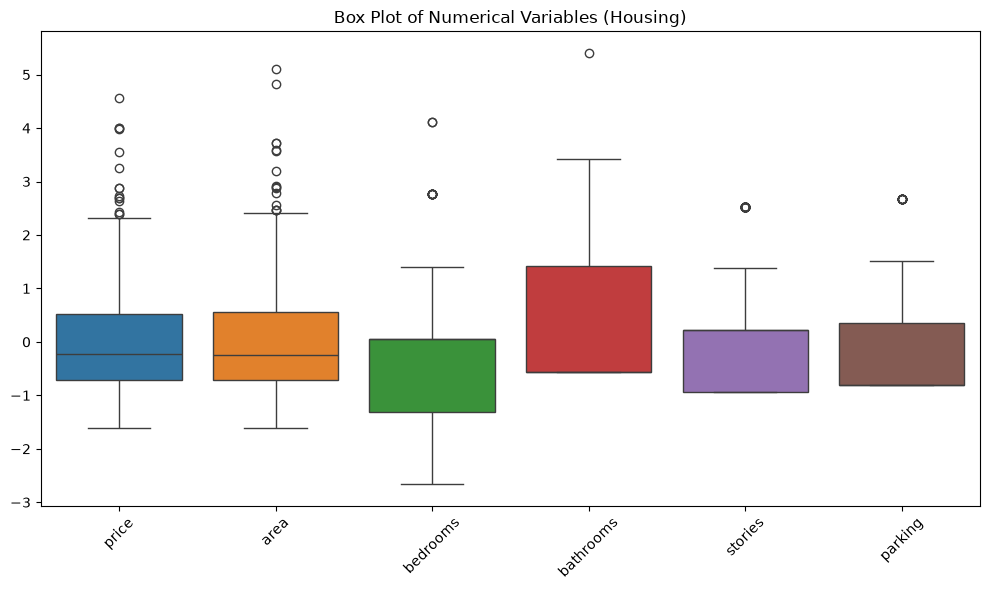

      Column         Q1         Q3        IQR    Lower      Upper  Outliers
0      price  3430000.0  5740000.0  2310000.0 -35000.0  9205000.0        15
1       area     3600.0     6360.0     2760.0   -540.0    10500.0        12
2   bedrooms        2.0        3.0        1.0      0.5        4.5        12
3  bathrooms        1.0        2.0        1.0     -0.5        3.5         1
4    stories        1.0        2.0        1.0     -0.5        3.5        41
5    parking        0.0        1.0        1.0     -1.5        2.5        12


In [7]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=std_df)
plt.title("Box Plot of Numerical Variables (Housing)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

rows = []
for col in numeric_cols:
    q1, q3 = df_clean[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df_clean[col] < lo) | (df_clean[col] > hi)).sum()
    rows.append([col, q1, q3, iqr, lo, hi, n_out])

iqr_table = pd.DataFrame(rows, columns=["Column", "Q1", "Q3", "IQR", "Lower", "Upper", "Outliers"])
print(iqr_table)

In [8]:
outlier_col = "price"
lo, hi = iqr_table.set_index("Column").loc[outlier_col, ["Lower", "Upper"]]
df_final = df_clean[df_clean[outlier_col].between(lo, hi)].copy()
print(f"Original rows: {len(df_clean)} | After outlier removal on {outlier_col}: {len(df_final)}")

Original rows: 545 | After outlier removal on price: 530


In [9]:
df_final.to_csv("preprocessed_dataset.csv", index=False)
print("Saved preprocessed dataset to preprocessed_dataset.csv")

Saved preprocessed dataset to preprocessed_dataset.csv
